In [1]:
import pandas as pd

train_df = pd.read_csv("../../data/train_preprocessed.csv")

X_train = train_df.drop("IsCanceled", axis=1)
y_train = train_df["IsCanceled"]

test_df = pd.read_csv("../../data/test_preprocessed.csv")

X_test = test_df.drop("IsCanceled", axis=1)
y_test = test_df["IsCanceled"]

train_df.drop("IsCanceled", axis=1)

,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,...,ReservedRoomType_C,ReservedRoomType_D,ReservedRoomType_E,ReservedRoomType_F,ReservedRoomType_G,ReservedRoomType_P,CustomerType_Contract,CustomerType_Group,CustomerType_Transient,CustomerType_Transient-Party
0,1.784280,-0.251414,1.557685,1.054201,-0.894336,-0.126248,0.288949,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.987752,-1.681652,0.586926,1.398043,-0.894336,-0.126248,0.288949,-0.246975,-0.055768,6.118802,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.614267,1.178824,0.064210,-0.321164,1.361015,1.917506,0.288949,5.077088,-0.055768,-0.163431,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.285744,-0.251414,1.557685,0.824974,-0.894336,-0.807499,-1.671900,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.438745,-1.681652,0.661600,-1.238074,1.361015,-0.126248,0.288949,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63459,-0.627748,-0.251414,-0.682527,1.283429,-0.894336,-0.807499,-1.671900,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
63460,0.047260,-0.251414,-0.607854,-1.238074,0.233339,0.555003,0.288949,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
63461,-0.636748,-1.681652,0.437579,-0.206550,-0.894336,-0.126248,0.288949,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
63462,1.757280,1.178824,-0.533180,-0.091936,0.233339,-1.488750,0.288949,-0.246975,-0.055768,-0.163431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [2]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (63464, 213)
y_train: (63464,)
X_test: (15866, 213)
y_test: (15866,)


In [4]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Model Training Completed")
print("Number of Features:", logistic_model.n_features_in_)
print("Number of Iterations:", logistic_model.n_iter_)

Model Training Completed
Number of Features: 213
Number of Iterations: [161]


In [5]:
y_pred = logistic_model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

print("\nActual Values:")
print(y_test.iloc[:10].values)

First 10 Predictions:
[0 0 0 1 0 0 0 0 0 0]

Actual Values:
[0 1 0 1 0 0 0 0 0 0]


In [7]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7661036177990672


In [8]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)


[[8022 1224]
 [2487 4133]]


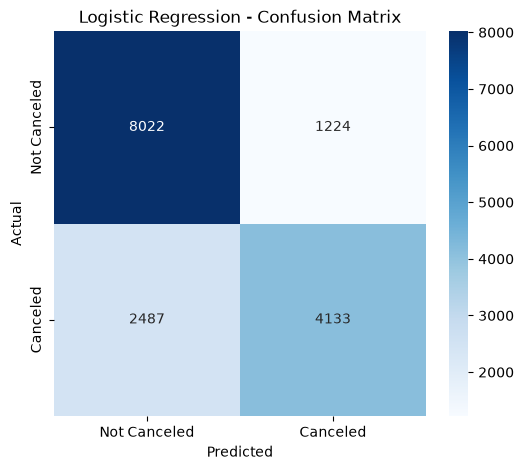

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Canceled", "Canceled"],
    yticklabels=["Not Canceled", "Canceled"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [10]:
error_rate = 1 - accuracy

print("Error Rate:", error_rate)

Error Rate: 0.23389638220093278


In [12]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.771513907037521


In [13]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print("Recall:", recall)


Recall: 0.6243202416918429


In [14]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print("F1-Score:", f1)

F1-Score: 0.6901561325874593
